# Comparación de modelos de clasificación - Proyecto HTA (SIS)

## KNN, Árbol de Decisión y Regresión Logística

- **Unidad:** un paciente hipertenso (cohorte 2022-2023, sin complicaciones previas y con atenciones en 2024).
- **Objetivo `y`:** ¿tuvo una complicación grave en 2024 (ACV/AIT, infarto, insuficiencia cardíaca, enfermedad renal o fallecimiento)? 1 = Sí, 0 = No.
- **Entrada:** `data/processed/dataset_consolidado.csv`, generado por `src/preprocessing.ipynb` (versión con códigos hipertensivos `I11.0`/`I12`/`I13` en el objetivo, sin fallecidos previos y con 6 variables nuevas).

## 1. Importaciones y Carga de Datos

In [36]:
import warnings
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, roc_curve, average_precision_score, brier_score_loss
)
from sklearn.calibration import calibration_curve

SEED = 42                     # semilla única para TODO lo aleatorio (split, submuestras, modelos, CV)
np.random.seed(SEED)

# Paleta de colores
color_primary = '#1f77b4'
color_secondary = '#ff7f0e'
color_accent1 = '#2E86AB'
color_accent2 = '#A23B72'

In [37]:
# Busca el dataset en la carpeta actual, en data/processed/ y en las carpetas superiores.
# Si está en otra carpeta, escribe aquí la ruta completa del CSV:
RUTA_MANUAL = None

def buscar_dataset(nombre='dataset_consolidado.csv'):
    if RUTA_MANUAL:
        return Path(RUTA_MANUAL)
    for p in [Path.cwd(), *Path.cwd().parents]:
        for d in (p, p / 'data' / 'processed'):
            if (d / nombre).exists():
                return d / nombre
    raise FileNotFoundError(f"No se encontró {nombre}. Ejecuta primero src/preprocessing.ipynb o escribe su ruta en RUTA_MANUAL.")

RUTA_DATASET = buscar_dataset()
df = pd.read_csv(RUTA_DATASET, index_col='paciente')
print("Dataset:", RUTA_DATASET)
print(f"Filas y columnas del dataset: {df.shape}")

# Controles: evitan modelar con un dataset roto (p. ej. la versión en que todas las presiones quedaron vacías)
assert df.index.is_unique, "Hay pacientes repetidos"
assert df['sin_medicion_pa'].mean() < 0.2, "Demasiados pacientes sin presión arterial: vuelve a ejecutar el preprocesamiento corregido"
df.head()

Dataset: C:\Users\ROG STRIX\Desktop\IA\ProyectoIA\data\processed\dataset_consolidado.csv
Filas y columnas del dataset: (419226, 37)


,edad,masculino,es_lima_frecuente,altitud_msnm,n_atenciones,n_emergencias,n_hospitalizaciones,dias_hosp,n_mediciones_pa,pas_media,...,n_diagnosticos,n_medicamentos,gasto_medicamentos,n_procedimientos,gasto_procedimientos,n_insumos,gasto_insumos,polifarmacia,sin_medicion_pa,y
paciente,,,,,,,,,,,,,,,,,,,,,
000015CA7003D37272A17DE250F6AFE9339F487360EC5001A9B5EBB811E10BFB,75.0,1,0,26.578,19,0,0,0.0,8,108.750000,...,12,8,12.000,36,0.00,1,0.000,1,0,0
000031B49CE1B8437CF896A1D20A1E7A5048DE009526346C0B3840D9E382C493,55.0,0,0,2452.990,37,4,0,0.0,28,135.892850,...,25,24,55.666,46,157.17,13,0.890,1,0,1
0000F157F4A508199E7AB5BC2C578CF314619454313BAA512AB5B2270467C510,63.0,0,1,137.800,51,1,0,0.0,12,123.083336,...,26,27,419.337,88,865.71,55,149.788,1,0,0
0001F8E39760B44806A289A871BFE29613282AC6E89F5E5D6D631745E8455338,63.0,0,0,136.760,40,1,0,0.0,23,128.608690,...,28,11,95.690,91,292.78,14,0.556,1,0,0
0004219B0B4CAB03727B60FFFA9B4F0EAD3271B27BB04B7BD326435BA973BD94,63.0,0,0,43.250,5,2,1,6.0,3,126.666664,...,11,15,64.616,33,517.43,12,23.028,1,0,0


## 2. Exploración rápida
Solo se revisa lo necesario para decidir el preprocesamiento: tamaño, filas repetidas, valores faltantes, tipos de dato y distribución del objetivo.

In [38]:
print(f"Filas (pacientes): {df.shape[0]:,} | Columnas: {df.shape[1]}")

Filas (pacientes): 419,226 | Columnas: 37


In [39]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 419226 entries, 000015CA7003D37272A17DE250F6AFE9339F487360EC5001A9B5EBB811E10BFB to FDDDE51BE42C8C319E09BDF8C74EF791D8F08CDFC0B8ECBC28AE1749A36B04BD
Data columns (total 37 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   edad                  419223 non-null  float64
 1   masculino             419226 non-null  int64  
 2   es_lima_frecuente     419226 non-null  int64  
 3   altitud_msnm          419226 non-null  float64
 4   n_atenciones          419226 non-null  int64  
 5   n_emergencias         419226 non-null  int64  
 6   n_hospitalizaciones   419226 non-null  int64  
 7   dias_hosp             419226 non-null  float64
 8   n_mediciones_pa       419226 non-null  int64  
 9   pas_media             402890 non-null  float64
 10  pas_max               402890 non-null  float64
 11  pad_media             402890 non-null  float64
 12  pad_max               402890 non-null  f

In [40]:
print(f"Pacientes repetidos (índice duplicado): {df.index.duplicated().sum():,}")
print(f"Filas con exactamente las mismas variables (incluida y): {df.duplicated().sum():,}")
print(f"  ...de ellas, con distinto y para las mismas X: "
      f"{df.drop(columns='y').duplicated().sum() - df.duplicated().sum():,}")

Pacientes repetidos (índice duplicado): 0
Filas con exactamente las mismas variables (incluida y): 0
  ...de ellas, con distinto y para las mismas X: 0


In [41]:
# Valores faltantes
faltantes = pd.DataFrame({'Faltantes': df.isnull().sum(),
                          'Porcentaje (%)': (df.isnull().mean() * 100).round(2)})
faltantes[faltantes['Faltantes'] > 0]

,Faltantes,Porcentaje (%)
edad,3,0.0
pas_media,16336,3.9
pas_max,16336,3.9
pad_media,16336,3.9
pad_max,16336,3.9
presion_pulso,16336,3.9
presion_pulso_max,16336,3.9
prop_pa_alta,16336,3.9
pas_ultima,16336,3.9


In [42]:
# Tipos de datos: ¿hay variables categóricas que codificar?
df.dtypes.value_counts()

int64      22
float64    15
Name: count, dtype: int64

In [43]:
# Distribución del objetivo
pd.DataFrame({'Pacientes': df['y'].value_counts(),
              'Proporción': df['y'].value_counts(normalize=True).round(4)})

,Pacientes,Proporción
y,,
0,395732,0.944
1,23494,0.056


In [44]:
# Escalas de las variables
df.drop(columns='y').describe().T[['mean', 'std', 'min', 'max']].round(2)

,mean,std,min,max
edad,65.29,14.27,16.00,110.00
masculino,0.33,0.47,0.00,1.00
es_lima_frecuente,0.28,0.45,0.00,1.00
altitud_msnm,916.24,1228.32,5.18,4705.40
n_atenciones,20.39,18.25,1.00,902.00
n_emergencias,1.05,2.53,0.00,343.00
n_hospitalizaciones,0.17,0.52,0.00,31.00
dias_hosp,1.37,10.72,0.00,991.00
n_mediciones_pa,10.28,9.35,0.00,276.00
pas_media,123.96,16.00,60.00,260.00


| Hallazgo | Consecuencia |
|---|---|
| Hay **valores faltantes** en las variables de presión arterial (pacientes sin ninguna medición, incluida `pas_ultima`) y en algunas edades | KNN y Regresión Logística no aceptan NaN → **imputar** |
| Todas las variables son **numéricas** (binarias 0/1, ordinales como `nivel_eess_max` y `n_comorbilidades`, o continuas) | **No** hace falta Label/One-Hot Encoding |
| Las **escalas son muy distintas** (gasto en miles de soles, días desde la última atención en cientos, variables 0/1) | **Estandarizar** para KNN y Regresión Logística (los árboles no lo necesitan) |
| La clase positiva es **≈5.6%** (desbalance ≈17:1) | El *accuracy* engaña → se usa **ROC-AUC** para elegir hiperparámetros, **PR-AUC** como métrica complementaria y **`class_weight='balanced'`** |
| `presion_pulso` (media) = `pas_media − pad_media` exactamente, y otras variables muy correlacionadas | Redundancia → se analiza con la **matriz de correlación** (sección 4.2) y se eliminan `dias_hosp` y `pad_media` |

### Modificaciones al dataset 

1. **Imputación por mediana (`SimpleImputer(strategy='median')`)**
   - Se usa la **mediana** y no la media porque presión, edad y gastos tienen colas largas y valores extremos que desplazarían la media.
   - **El imputador solo aprende del train:** `imputer.fit(X_train)` calcula las medianas **únicamente con el conjunto de entrenamiento**. Después, `transform` usa esas medianas para rellenar los vacíos de train **y** de test. El test nunca aporta información (no hay *data leakage*). En los *pipelines* y en la validación cruzada esto ocurre dentro de cada fold.
   - **No se eliminan filas:** los pacientes sin medición de presión tienen **más** complicaciones que el resto. Borrarlos sesgaría la muestra y haría perder un grupo de mayor riesgo.
   - **Se conserva `sin_medicion_pa`**: le indica al modelo que esa presión fue imputada, así que la información de "nunca se midió" no se pierde al imputar.
2. **Estandarización (`StandardScaler`)**, solo para KNN y Regresión Logística, también ajustada **solo con train**. KNN usa distancias y la regresión logística se optimiza por gradiente con regularización: sin escalar, las variables con números grandes (gasto) dominarían. El árbol se entrena **sin escalar**, porque dividen por umbrales y la escala no les afecta.
3. **Desbalance**: `class_weight='balanced'` en el Árbol y la Regresión Logística. Cada paciente con complicación pesa ≈18 veces más en el entrenamiento, así el modelo no puede "ganar" diciendo siempre *sin complicación*. KNN no admite pesos por clase. No se usa **SMOTE** porque crearía pacientes sintéticos con valores intermedios en variables 0/1, y `class_weight` logra el mismo efecto sin inventar datos. **El test nunca se balancea**: debe reflejar la realidad.
4. **Métrica de selección: ROC-AUC.** Con un 5% de positivos, un modelo que siempre dice "0" tiene un 95% de accuracy. El AUC mide cómo el modelo **ordena** a los pacientes por riesgo, sin depender del umbral ni del desbalance.

## 3. Separación de variables y División Entrenamiento-Prueba

In [45]:
y = df['y']
X = df.drop(columns='y')

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,           # 80% entrenamiento, 20% prueba
    random_state=SEED,       # Para resultados replicables
    stratify=y               # Mantiene la proporción de complicaciones en ambos conjuntos
)

pd.DataFrame({
    'Conjunto': ['Entrenamiento', 'Prueba'],
    'Muestras': [X_train.shape[0], X_test.shape[0]],
    'Características': [X_train.shape[1], X_test.shape[1]],
    'Complicaciones': [y_train.sum(), y_test.sum()],
    '% Complicaciones': [round(y_train.mean() * 100, 2), round(y_test.mean() * 100, 2)]})

,Conjunto,Muestras,Características,Complicaciones,% Complicaciones
0,Entrenamiento,335380,36,18795,5.6
1,Prueba,83846,36,4699,5.6


## 4. Preprocesamiento

### 4.1 Imputación por mediana (fit SOLO con train)

In [46]:
imputer = SimpleImputer(strategy='median')
imputer.fit(X_train)                          # las medianas se calculan SOLO con train

X_train_imp = pd.DataFrame(imputer.transform(X_train), columns=X.columns, index=X_train.index)
X_test_imp  = pd.DataFrame(imputer.transform(X_test),  columns=X.columns, index=X_test.index)   # medianas de TRAIN

medianas = pd.Series(imputer.statistics_, index=X.columns)
print("Medianas aprendidas en train (columnas con faltantes):")
print(medianas[X_train.columns[X_train.isnull().any()]].round(2).to_string())
print(f"\nFaltantes después -> train: {X_train_imp.isnull().sum().sum()} | test: {X_test_imp.isnull().sum().sum()}")

Medianas aprendidas en train (columnas con faltantes):
edad                  67.00
pas_media            122.00
pas_max              144.00
pad_media             71.31
pad_max               84.00
presion_pulso         50.00
presion_pulso_max     70.00
prop_pa_alta           0.20
pas_ultima           120.00

Faltantes después -> train: 0 | test: 0


### 4.2 Matriz de correlación: ¿hay columnas redundantes?
Se calcula **solo con el train** (ya imputado), para que el test no influya en la decisión de eliminar columnas.
- **Pearson** mide la relación lineal.
- **Spearman** mide la relación monótona (por rangos). Es más robusta en variables con muchos ceros y colas largas, como los conteos y gastos.

Dos variables con |r| ≥ 0.9 aportan casi la misma información y una es candidata a eliminarse. Entre 0.7 y 0.9 la redundancia es parcial.

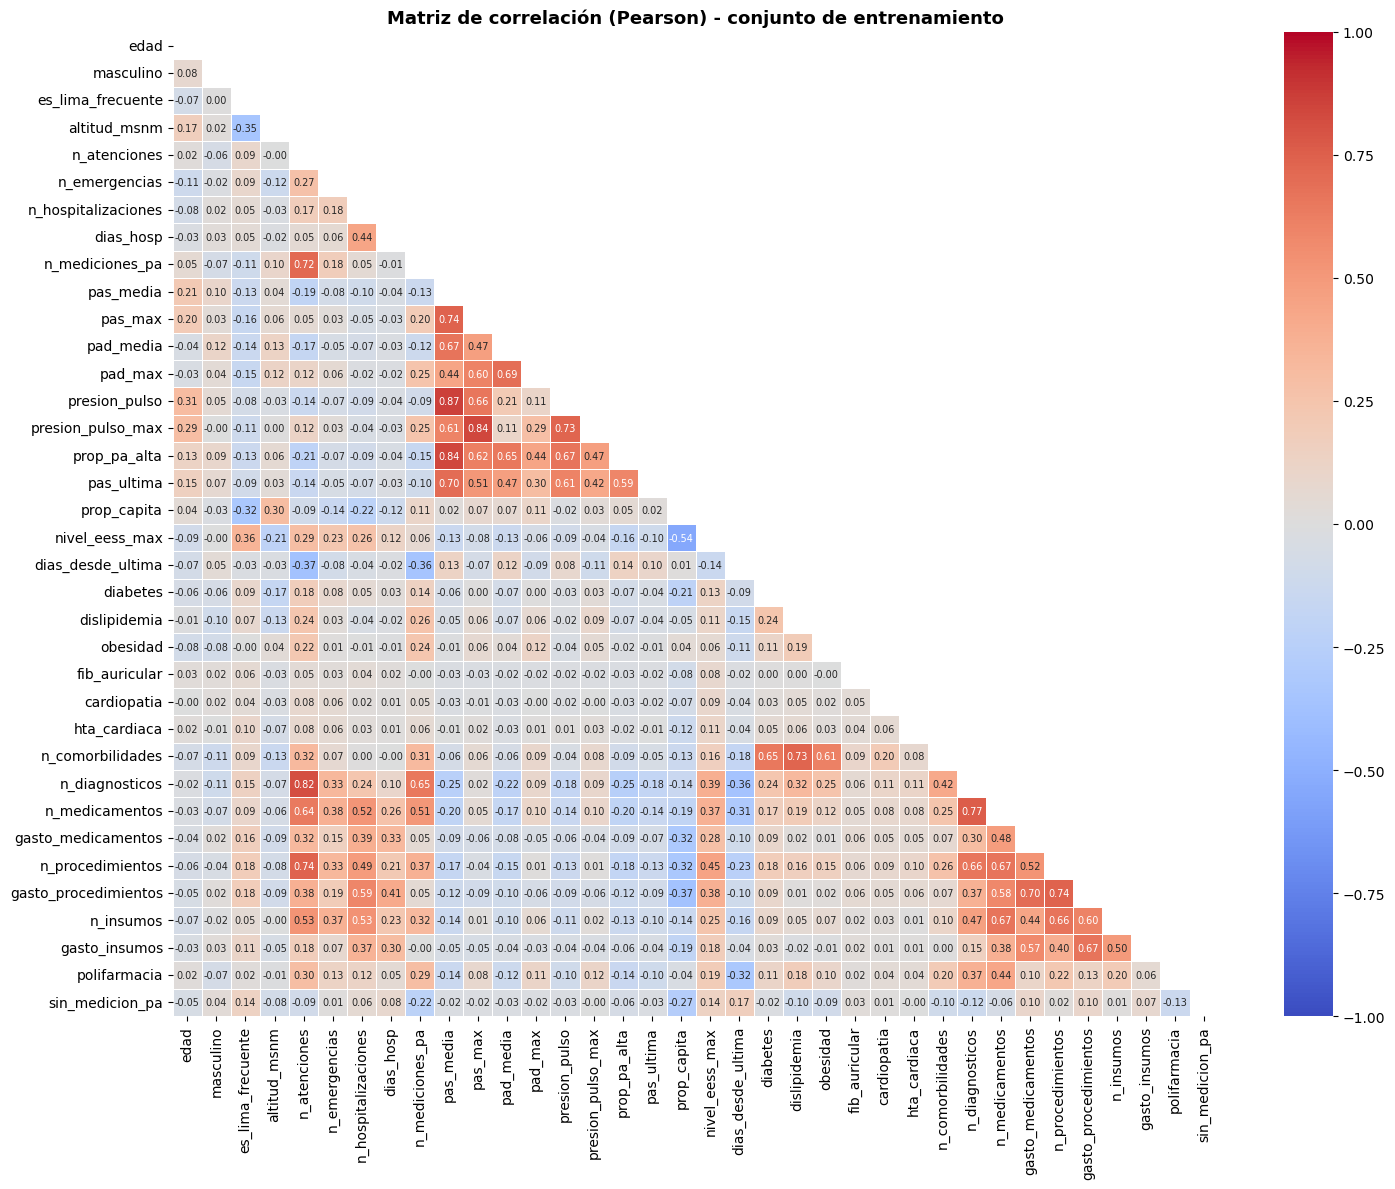

In [47]:
corr = X_train_imp.corr(method='pearson')

mascara = np.triu(np.ones_like(corr, dtype=bool))      # solo el triángulo inferior
fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(corr, mask=mascara, cmap='coolwarm', center=0, vmin=-1, vmax=1,
            annot=True, fmt='.2f', annot_kws={'size': 7}, linewidths=0.5, ax=ax)
ax.set_title('Matriz de correlación (Pearson) - conjunto de entrenamiento', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [48]:
def pares_correlacionados(matriz, umbral):
    # Pares de variables con |correlación| >= umbral, ordenados de mayor a menor
    triangulo = matriz.where(np.triu(np.ones(matriz.shape, dtype=bool), k=1)).stack()
    pares = triangulo[triangulo.abs() >= umbral].sort_values(key=abs, ascending=False)
    return pares.rename('r').round(3).reset_index().rename(columns={'level_0': 'Variable 1', 'level_1': 'Variable 2'})

corr_spearman = X_train_imp.corr(method='spearman')
print("Pares con |r| >= 0.7 (Pearson):")
display(pares_correlacionados(corr, 0.7))
print("Pares con |r| >= 0.7 (Spearman):")
display(pares_correlacionados(corr_spearman, 0.7))

Pares con |r| >= 0.7 (Pearson):


,Variable 1,Variable 2,r
0,pas_media,presion_pulso,0.866
1,pas_max,presion_pulso_max,0.841
2,pas_media,prop_pa_alta,0.839
3,n_atenciones,n_diagnosticos,0.818
4,n_diagnosticos,n_medicamentos,0.765
5,n_procedimientos,gasto_procedimientos,0.742
6,n_atenciones,n_procedimientos,0.741
7,pas_media,pas_max,0.741
8,presion_pulso,presion_pulso_max,0.729
9,dislipidemia,n_comorbilidades,0.727


Pares con |r| >= 0.7 (Spearman):


,Variable 1,Variable 2,r
0,n_hospitalizaciones,dias_hosp,0.997
1,n_atenciones,n_diagnosticos,0.856
2,pas_media,presion_pulso,0.848
3,pas_media,prop_pa_alta,0.829
4,pas_max,presion_pulso_max,0.823
5,nivel_eess_max,gasto_procedimientos,0.819
6,n_diagnosticos,n_medicamentos,0.801
7,n_atenciones,n_mediciones_pa,0.773
8,gasto_procedimientos,gasto_insumos,0.761
9,prop_capita,gasto_medicamentos,-0.758


In [49]:
# Relación de cada variable con el objetivo: ante dos variables redundantes, conviene quedarse con la más relacionada con y
X_train_imp.corrwith(y_train).sort_values(key=abs, ascending=False).round(3).to_frame('Correlación con y')

,Correlación con y
prop_capita,-0.092
nivel_eess_max,0.081
n_procedimientos,0.080
edad,0.077
gasto_procedimientos,0.073
n_medicamentos,0.072
gasto_medicamentos,0.071
diabetes,0.066
n_hospitalizaciones,0.060
n_diagnosticos,0.055


#### Interpretación: ¿qué columnas eliminar?

| Par | Correlación | Diagnóstico | Recomendación |
|---|---|---|---|
| `n_hospitalizaciones` – `dias_hosp` | Spearman ≈ **0.997** | Casi idénticas: la mayoría de pacientes tiene 0 en ambas. Pearson es menor solo por algunos días extremos | **Eliminar `dias_hosp`**: se queda `n_hospitalizaciones`, que tiene mayor correlación con `y` |
| `presion_pulso` = `pas_media` − `pad_media` | Dependencia lineal **exacta** (no se ve en un solo par) | Una de las tres es redundante. Para la Regresión Logística es colinealidad perfecta | **Eliminar `pad_media`**: es la de menor relación con `y` (≈0.00), y su información queda en `pas_media` y `presion_pulso` |
| `pas_media` – `presion_pulso` / `prop_pa_alta`; `pas_max` – `presion_pulso_max` | 0.84 – 0.87 | Alta, pero < 0.9: miden aspectos distintos (nivel, rigidez arterial, frecuencia de PA elevada) | Mantener |
| `n_atenciones` – `n_diagnosticos` – `n_medicamentos` – `n_procedimientos` | 0.75 – 0.86 | Todas reflejan la intensidad de uso del sistema de salud | Mantener (redundancia parcial) |

**Impacto esperado:** bajo.
- Los árboles eligen una sola variable por división, así que la redundancia no les afecta.
- En la Regresión Logística, la regularización L2 ya amortigua la colinealidad (todas las combinaciones de C dieron el mismo AUC).
- Eliminar `dias_hosp` y `pad_media` sobre todo **simplifica** el modelo y hace **interpretables** los coeficientes de presión, sin pérdida esperada de AUC.
- **Decisión del equipo: se eliminan `dias_hosp` y `pad_media`** (celda siguiente).

**Variables nuevas del preprocesamiento.** Varias de ellas están correlacionadas con otras por construcción y conviene revisarlas en la tabla de pares:
- `n_comorbilidades` es la **suma** de `diabetes`, `dislipidemia`, `obesidad`, `fib_auricular` y `cardiopatia`: hay dependencia lineal exacta. Para la regresión logística con regularización L2 no es un problema numérico, pero sus coeficientes se reparten entre el recuento y los indicadores y deben interpretarse juntos.
- `pas_ultima` suele correlacionar con `pas_media` y `pas_max` (es una de las mediciones que las forman), pero aporta el estado **más reciente** del paciente.
- `prop_capita` se relaciona con las variables `gasto_*` (el gasto es 0 en las atenciones por cápita).

Si alguno de estos pares supera |r| ≥ 0.9, se puede agregar a `COLS_ELIMINAR` con el mismo criterio de la tabla anterior (conservar la más relacionada con `y`).

In [50]:
# Eliminar columnas redundantes según la matriz de correlación (calculada solo con train)
COLS_ELIMINAR = ['dias_hosp', 'pad_media']

X           = X.drop(columns=COLS_ELIMINAR)
X_train     = X_train.drop(columns=COLS_ELIMINAR)
X_test      = X_test.drop(columns=COLS_ELIMINAR)
X_train_imp = X_train_imp.drop(columns=COLS_ELIMINAR)
X_test_imp  = X_test_imp.drop(columns=COLS_ELIMINAR)

print(f"Variables restantes: {X_train.shape[1]}")

Variables restantes: 34


### 4.3 Estandarización (fit SOLO con train)
$x_{std} = \frac{x - \mu_{train}}{\sigma_{train}}$

In [51]:
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train_imp), columns=X.columns, index=X_train.index)
X_test_scaled  = pd.DataFrame(scaler.transform(X_test_imp),      columns=X.columns, index=X_test.index)

cols_ej = ['edad', 'pas_media', 'altitud_msnm', 'gasto_procedimientos']
pd.DataFrame({
    'Antes (media)':   X_train_imp[cols_ej].mean(),
    'Antes (std)':     X_train_imp[cols_ej].std(),
    'Después (media)': X_train_scaled[cols_ej].mean(),
    'Después (std)':   X_train_scaled[cols_ej].std()
}).round(3)

,Antes (media),Antes (std),Después (media),Después (std)
edad,65.278,14.279,-0.0,1.0
pas_media,123.881,15.712,0.0,1.0
altitud_msnm,915.842,1227.614,-0.0,1.0
gasto_procedimientos,305.631,849.296,0.0,1.0


### 4.4 Conjunto de validación
Para elegir hiperparámetros, el entrenamiento se divide de nuevo en *training* (80%) y *validación* (20%). **El test no se toca hasta el final.**

In [52]:
idx_tr, idx_val = train_test_split(X_train.index, test_size=0.2, random_state=SEED, stratify=y_train)
y_tr, y_val = y_train.loc[idx_tr], y_train.loc[idx_val]

def auc_tr_val(modelo, X_tr_, X_val_):
    # Entrena con training y devuelve (AUC train, AUC validación)
    modelo.fit(X_tr_, y_tr)
    return (roc_auc_score(y_tr, modelo.predict_proba(X_tr_)[:, 1]),
            roc_auc_score(y_val, modelo.predict_proba(X_val_)[:, 1]))

print(f"Training: {len(idx_tr):,} | Validación: {len(idx_val):,}")

Training: 268,304 | Validación: 67,076


---

## 5. K-Nearest Neighbors (KNN)

KNN clasifica a un paciente según la mayoría de votos de sus $k$ vecinos más cercanos (distancia euclidiana). Necesita datos **estandarizados**.

### 5.1 Efecto del Hiperparámetro k
KNN es lento para predecir (calcula la distancia a todos los pacientes del train). Por eso el ajuste de $k$ se hace con una **submuestra estratificada de 50,000 pacientes** del training, más el conjunto de validación completo. El modelo final se entrena con **todo** el train.

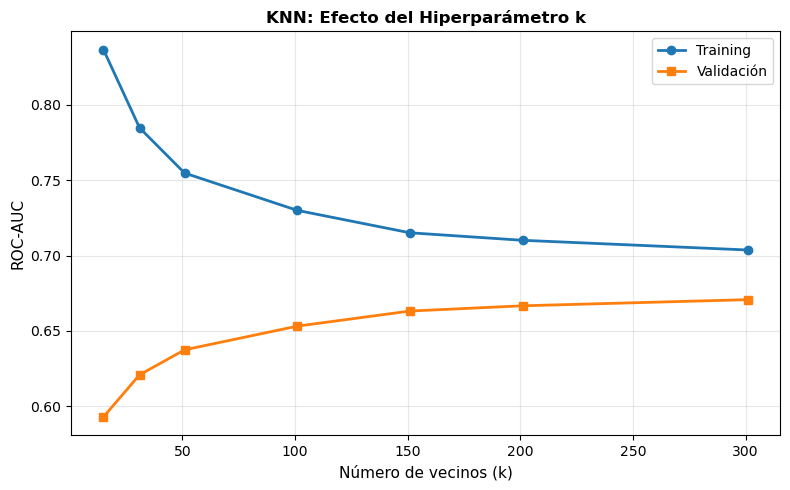

ROC-AUC por k:
  k= 15: Train=0.8367, Val=0.5928, Brecha=0.2439
  k= 31: Train=0.7849, Val=0.6208, Brecha=0.1641
  k= 51: Train=0.7548, Val=0.6374, Brecha=0.1174
  k=101: Train=0.7300, Val=0.6531, Brecha=0.0769
  k=151: Train=0.7151, Val=0.6631, Brecha=0.0520
  k=201: Train=0.7101, Val=0.6666, Brecha=0.0435
  k=301: Train=0.7037, Val=0.6707, Brecha=0.0330


In [53]:
# Submuestra estratificada de training para el ajuste de k
idx_tr_knn, _ = train_test_split(idx_tr, train_size=50_000, random_state=SEED, stratify=y_tr)
y_tr_knn = y_tr.loc[idx_tr_knn]

k_values = [15, 31, 51, 101, 151, 201, 301]   # se amplía la grilla: antes el mejor k era siempre el máximo (101)
train_scores_knn, val_scores_knn = [], []

for k in k_values:
    knn_temp = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
    knn_temp.fit(X_train_scaled.loc[idx_tr_knn], y_tr_knn)
    train_scores_knn.append(roc_auc_score(y_tr_knn, knn_temp.predict_proba(X_train_scaled.loc[idx_tr_knn])[:, 1]))
    val_scores_knn.append(roc_auc_score(y_val, knn_temp.predict_proba(X_train_scaled.loc[idx_val])[:, 1]))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(k_values, train_scores_knn, marker='o', label='Training', color=color_primary, linewidth=2)
ax.plot(k_values, val_scores_knn, marker='s', label='Validación', color=color_secondary, linewidth=2)
ax.set_xlabel('Número de vecinos (k)', fontsize=11)
ax.set_ylabel('ROC-AUC', fontsize=11)
ax.set_title('KNN: Efecto del Hiperparámetro k', fontsize=12, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("ROC-AUC por k:")
for k, tr, val in zip(k_values, train_scores_knn, val_scores_knn):
    print(f"  k={k:3d}: Train={tr:.4f}, Val={val:.4f}, Brecha={tr - val:.4f}")

In [54]:
best_k = k_values[int(np.argmax(val_scores_knn))]
print(f"Mejor k: {best_k}")

# Modelo final con ese k en TODO el entrenamiento; se evalúa UNA vez en test
knn_final = KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1)
knn_final.fit(X_train_scaled, y_train)
y_proba_knn = knn_final.predict_proba(X_test_scaled)[:, 1]
y_pred_knn = (y_proba_knn >= 0.5).astype(int)
print(f"ROC-AUC en TEST: {roc_auc_score(y_test, y_proba_knn):.4f}")

Mejor k: 301
ROC-AUC en TEST: 0.6809


#### Justificación del hiperparámetro elegido (KNN)
- El `k` elegido es el de mayor AUC en validación dentro de la grilla `[15, 31, 51, 101, 151, 201, 301]` (ver la tabla de arriba). La grilla se amplió respecto de la versión anterior (que terminaba en 101) porque el mejor `k` era siempre el máximo: no se sabía dónde estaba el óptimo.
- Con `k` pequeño, KNN **memoriza** el entrenamiento: la brecha entre el AUC de train y el de validación es grande. Al aumentar `k`, la brecha baja y la validación sube.
- Si la curva de validación se **aplana** en los `k` más altos, el óptimo está cerca: seguir aumentando `k` daría ganancias marginales a cambio de predicciones más lentas. Si sigue subiendo en 301, el mejor `k` está aún más arriba.
- En la ejecución anterior (grilla hasta 101) se eligió k = 101: AUC validación 0.653, test 0.662.

#### ¿Por qué KNN necesita un k tan grande?
En la versión anterior, el mejor $k$ resultó ser siempre **el mayor valor disponible**. Esto no es casualidad: refleja que **KNN suele ser el modelo más débil para datos tabulares administrativos y médicos** como estos, por tres motivos:

1. **Alta dimensionalidad (maldición de la dimensionalidad).** Con ~35 variables heterogéneas (conteos, gastos, indicadores 0/1, presión), las distancias euclidianas entre pacientes se vuelven parecidas: el vecino "más cercano" no es mucho más cercano que uno lejano. Además, KNN da el **mismo peso a todas las variables**, incluidas las que aportan poco (p. ej. `dislipidemia`, `pad_max`), y estas meten ruido en la distancia. Con pocos vecinos el voto es casi aleatorio; solo al promediar muchos (k grande) el ruido se cancela. Por eso el AUC sube con k.
2. **Desbalance de clases (≈5.6% de positivos).** Entre los k vecinos de cualquier paciente hay, en promedio, solo un 5-6% con complicación. Con el umbral de 0.5 casi nunca se alcanza la mayoría, así que KNN **no predice ninguna complicación** (recall = 0). Además, KNN no admite `class_weight`. Un k grande solo mejora el **orden** de las probabilidades (AUC), no la detección.
3. **Costo de cómputo en la inferencia.** KNN no "aprende" un modelo: para predecir a cada paciente calcula la distancia a los **~340,000 pacientes del train**. Es el modelo más lento de predecir, y el costo crece con el tamaño de los datos. Por eso su ajuste se hizo sobre una submuestra, mientras que el árbol y la regresión logística, una vez entrenados, predicen casi al instante.

En cambio, los **árboles** eligen solo las variables útiles en cada división y la **regresión logística** aprende un peso por variable. Ambos manejan mejor las variables irrelevantes y el desbalance (`class_weight='balanced'`). Esto coincide con lo reportado para datos tabulares, donde los modelos basados en árboles y los lineales suelen superar a los basados en distancias.

---

## 6. Árboles de Decisión

Particionan el espacio con preguntas sobre las variables ("¿edad > 70?"). No necesitan estandarización: se entrenan con `X_train_imp`. Se usa `class_weight='balanced'`.

### 6.1 Efecto de la Profundidad

Mejor profundidad: 7


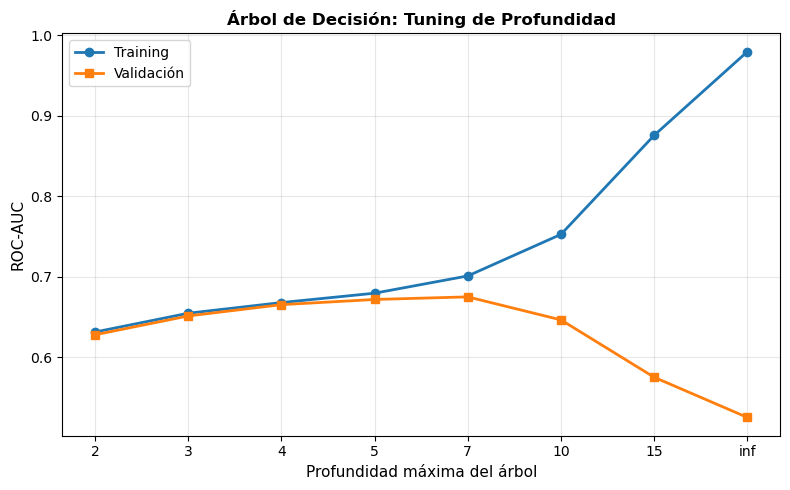

ROC-AUC por profundidad:
  depth=2  : Train=0.6314, Val=0.6281, Brecha=0.0034
  depth=3  : Train=0.6548, Val=0.6514, Brecha=0.0034
  depth=4  : Train=0.6680, Val=0.6654, Brecha=0.0026
  depth=5  : Train=0.6797, Val=0.6719, Brecha=0.0078
  depth=7  : Train=0.7011, Val=0.6751, Brecha=0.0260
  depth=10 : Train=0.7527, Val=0.6465, Brecha=0.1062
  depth=15 : Train=0.8757, Val=0.5753, Brecha=0.3004
  depth=inf: Train=0.9796, Val=0.5254, Brecha=0.4542


In [55]:
depths = [2, 3, 4, 5, 7, 10, 15, None]
train_scores_dt, val_scores_dt = [], []

for depth in depths:
    dt_temp = DecisionTreeClassifier(max_depth=depth, min_samples_split=20,
                                     class_weight='balanced', random_state=SEED)
    tr, val = auc_tr_val(dt_temp, X_train_imp.loc[idx_tr], X_train_imp.loc[idx_val])
    train_scores_dt.append(tr)
    val_scores_dt.append(val)

best_depth = depths[int(np.argmax(val_scores_dt))]
print(f"Mejor profundidad: {best_depth}")

fig, ax = plt.subplots(figsize=(8, 5))
depths_plot = [str(d) if d else 'inf' for d in depths]
x_pos = np.arange(len(depths_plot))
ax.plot(x_pos, train_scores_dt, marker='o', label='Training', color=color_primary, linewidth=2)
ax.plot(x_pos, val_scores_dt, marker='s', label='Validación', color=color_secondary, linewidth=2)
ax.set_xlabel('Profundidad máxima del árbol', fontsize=11)
ax.set_ylabel('ROC-AUC', fontsize=11)
ax.set_title('Árbol de Decisión: Tuning de Profundidad', fontsize=12, fontweight='bold')
ax.set_xticks(x_pos)
ax.set_xticklabels(depths_plot)
ax.legend(fontsize=10)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("ROC-AUC por profundidad:")
for depth, tr, val in zip(depths_plot, train_scores_dt, val_scores_dt):
    print(f"  depth={depth:3s}: Train={tr:.4f}, Val={val:.4f}, Brecha={tr - val:.4f}")

### 6.1b Profundidad y tamaño mínimo de las hojas
La curva anterior solo mueve la profundidad. Un árbol también se puede regularizar exigiendo un **mínimo de pacientes por hoja** (`min_samples_leaf`): así cada hoja estima su probabilidad con suficientes pacientes y se evitan hojas de 20 pacientes con 1 o 2 positivos. Se prueba una grilla pequeña de ambos hiperparámetros juntos.

Mejor combinación: max_depth=10, min_samples_leaf=2000 (AUC val=0.6813)


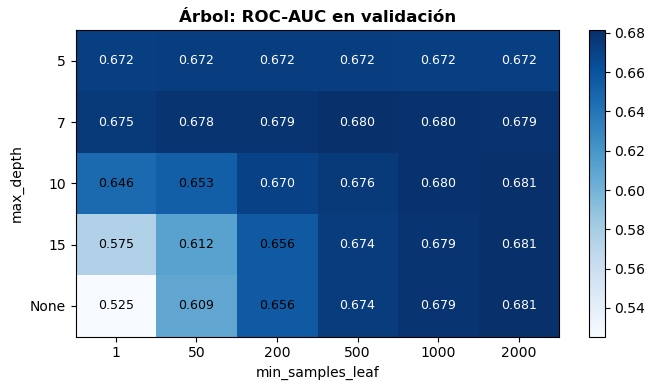

In [56]:
leafs = [1, 50, 200, 500, 1000, 2000]
depths_grid = [5, 7, 10, 15, None]
filas_dt = []
for depth in depths_grid:
    for leaf in leafs:
        dt_temp = DecisionTreeClassifier(max_depth=depth, min_samples_split=20, min_samples_leaf=leaf,
                                         class_weight='balanced', random_state=SEED)
        tr, val = auc_tr_val(dt_temp, X_train_imp.loc[idx_tr], X_train_imp.loc[idx_val])
        filas_dt.append({'max_depth': 'None' if depth is None else depth, 'min_samples_leaf': leaf, 'AUC train': tr, 'AUC val': val})
grid_dt = pd.DataFrame(filas_dt)
mejor_dt = grid_dt.loc[grid_dt['AUC val'].idxmax()]
best_depth = None if mejor_dt['max_depth'] == 'None' else int(mejor_dt['max_depth'])
best_leaf = int(mejor_dt['min_samples_leaf'])
print(f"Mejor combinación: max_depth={best_depth}, min_samples_leaf={best_leaf} (AUC val={mejor_dt['AUC val']:.4f})")

tabla = grid_dt.pivot(index='max_depth', columns='min_samples_leaf', values='AUC val').reindex([str(d) if d is None else d for d in depths_grid])
fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(tabla.values, cmap='Blues', aspect='auto')
for i in range(tabla.shape[0]):
    for j in range(tabla.shape[1]):
        v = tabla.values[i, j]
        ax.text(j, i, f'{v:.3f}', ha='center', va='center', color='white' if v > np.nanmean(tabla.values) else 'black', fontsize=9)
ax.set_xticks(range(len(leafs)), leafs); ax.set_yticks(range(len(depths_grid)), [str(d) for d in depths_grid])
ax.set_xlabel('min_samples_leaf'); ax.set_ylabel('max_depth')
ax.set_title('Árbol: ROC-AUC en validación', fontsize=12, fontweight='bold')
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

**Cómo leerlo.** Sin mínimo por hoja (`min_samples_leaf=1`), los árboles profundos sobreajustan y su AUC cae. Con hojas de 200-500 pacientes, incluso un árbol sin límite de profundidad se mantiene estable, porque el tamaño de las hojas ya frena el crecimiento. Si la mejor celda está en la fila o columna del borde, conviene ampliar la grilla en esa dirección.

In [57]:
# Árbol final con la mejor profundidad, entrenado con TODO el train
dt_final = DecisionTreeClassifier(max_depth=best_depth, min_samples_split=20, min_samples_leaf=best_leaf,
                                  class_weight='balanced', random_state=SEED)
dt_final.fit(X_train_imp, y_train)
y_pred_dt = dt_final.predict(X_test_imp)
y_proba_dt = dt_final.predict_proba(X_test_imp)[:, 1]
print(f"ROC-AUC en TEST: {roc_auc_score(y_test, y_proba_dt):.4f}")

ROC-AUC en TEST: 0.6745


#### Justificación de los hiperparámetros elegidos (Árbol)
- Se elige la combinación de profundidad y `min_samples_leaf` con mayor AUC en validación (sección 6.1b).
- En la curva de profundidad (con `min_samples_leaf=1`), el AUC de validación sube hasta una profundidad intermedia y después cae por **sobreajuste**: el AUC de train sigue subiendo mientras el de validación baja. En la ejecución anterior el óptimo fue profundidad 7 (AUC validación 0.675, test 0.674), con la profundidad 5 prácticamente empatada (0.672).
- Exigir un mínimo de pacientes por hoja permite árboles más profundos sin sobreajustar. Si dos combinaciones empatan (diferencia < 0.001), conviene la más simple (menos profundidad), que es más fácil de interpretar.

### 6.2 Importancia de Características

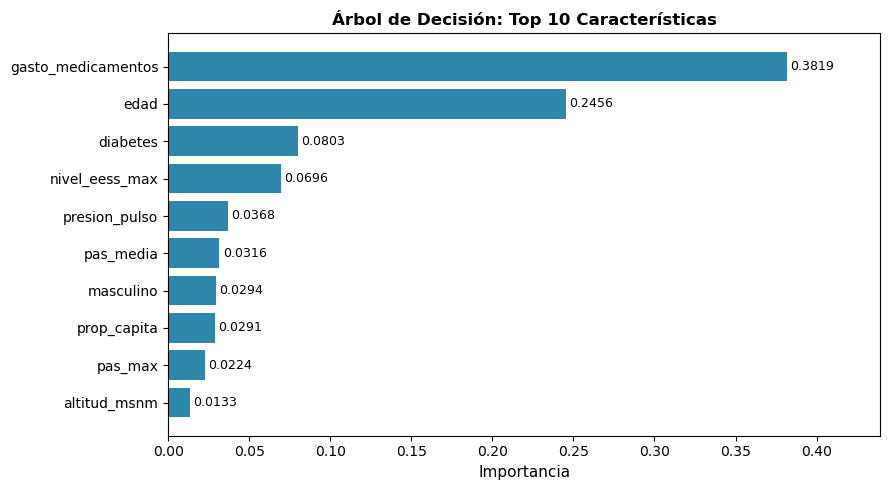

In [58]:
def plot_importancia(modelo, titulo, color):
    imp = pd.DataFrame({'feature': X.columns, 'importance': modelo.feature_importances_}) \
            .sort_values('importance', ascending=False).head(10)
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.barh(imp['feature'], imp['importance'], color=color)
    for i, (_, row) in enumerate(imp.iterrows()):
        ax.text(row['importance'] + 0.002, i, f"{row['importance']:.4f}", va='center', fontsize=9)
    ax.invert_yaxis()
    ax.set_xlabel('Importancia', fontsize=11)
    ax.set_title(titulo, fontsize=12, fontweight='bold')
    ax.set_xlim([0, imp['importance'].max() * 1.15])
    plt.tight_layout()
    plt.show()

plot_importancia(dt_final, 'Árbol de Decisión: Top 10 Características', color_accent1)

---

## 7. Regresión Logística

Modelo lineal que estima $P(y=1|x) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + ... + \beta_n x_n)}}$. Necesita datos **estandarizados**. Se usa `class_weight='balanced'` y regularización L2.

### 7.1 Tuning de Hiperparámetros (ejercicio del tutorial)
Se prueban los solvers `lbfgs`, `saga` y `liblinear` con `C ∈ {0.0001, 0.001, 0.01, 0.1, 1, 10}` ($C$ bajo = regularización fuerte). Penalización L2 (la de por defecto). *Nota:* se quitó el argumento `l1_ratio=0`, que en las versiones recientes de scikit-learn solo genera advertencias cuando la penalización es L2.

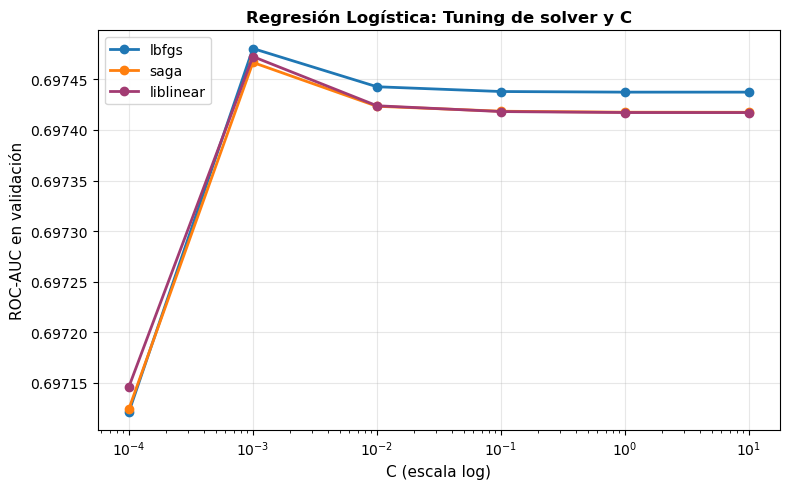

solver,lbfgs,liblinear,saga
C,,,
0.0001,0.6971,0.6971,0.6971
0.0010,0.6975,0.6975,0.6975
0.0100,0.6974,0.6974,0.6974
0.1000,0.6974,0.6974,0.6974
1.0000,0.6974,0.6974,0.6974
10.0000,0.6974,0.6974,0.6974


In [59]:
solvers = ['lbfgs', 'saga', 'liblinear']
C_values = [0.0001, 0.001, 0.01, 0.1, 1.0, 10]   # se agregan C más bajos: con 0.01-10 todas las combinaciones empataban
resultados_lr = []

with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    for solver in solvers:
        for C in C_values:
            lr_temp = LogisticRegression(C=C, solver=solver, class_weight='balanced',
                                         max_iter=1000, random_state=SEED)
            tr, val = auc_tr_val(lr_temp, X_train_scaled.loc[idx_tr], X_train_scaled.loc[idx_val])
            resultados_lr.append({'solver': solver, 'C': C, 'AUC train': tr, 'AUC val': val})

resultados_lr = pd.DataFrame(resultados_lr)

fig, ax = plt.subplots(figsize=(8, 5))
for solver, color in zip(solvers, [color_primary, color_secondary, color_accent2]):
    r = resultados_lr[resultados_lr['solver'] == solver]
    ax.plot(r['C'], r['AUC val'], marker='o', label=solver, color=color, linewidth=2)
ax.set_xscale('log')
ax.set_xlabel('C (escala log)', fontsize=11)
ax.set_ylabel('ROC-AUC en validación', fontsize=11)
ax.set_title('Regresión Logística: Tuning de solver y C', fontsize=12, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

resultados_lr.pivot(index='C', columns='solver', values='AUC val').round(4)

In [60]:
mejor_lr = resultados_lr.loc[resultados_lr['AUC val'].idxmax()]
best_solver, best_C = mejor_lr['solver'], mejor_lr['C']
print(f"Mejor combinación: solver={best_solver}, C={best_C} (AUC val={mejor_lr['AUC val']:.4f})")

lr_final = LogisticRegression(C=best_C, solver=best_solver, class_weight='balanced',
                              max_iter=1000, random_state=SEED)
lr_final.fit(X_train_scaled, y_train)
y_pred_lr = lr_final.predict(X_test_scaled)
y_proba_lr = lr_final.predict_proba(X_test_scaled)[:, 1]
print(f"ROC-AUC en TEST: {roc_auc_score(y_test, y_proba_lr):.4f}")

Mejor combinación: solver=lbfgs, C=0.001 (AUC val=0.6975)
ROC-AUC en TEST: 0.6925


### 7.1b ¿Mejora la regresión logística con `log1p` en conteos y gastos?
Los conteos (`n_*`) y gastos (`gasto_*`) son muy asimétricos: la mayoría de pacientes tiene valores bajos y unos pocos, valores enormes. Un modelo lineal asume que pasar de 0 a 10 procedimientos pesa lo mismo que pasar de 500 a 510. Con `log1p(x) = log(1 + x)` las diferencias se miden en escala relativa. Se compara en validación con la mejor combinación anterior. Es un experimento: el modelo final no cambia.

In [61]:
cols_log = [c for c in X.columns if c.startswith(('n_', 'gasto_')) or c in ('dias_desde_ultima',)]
def con_log(Xd):
    Xd = Xd.copy()
    Xd[cols_log] = np.log1p(Xd[cols_log].clip(lower=0))
    return Xd

esc_log = StandardScaler().fit(con_log(X_train_imp.loc[idx_tr]))
lr_log = LogisticRegression(C=best_C, solver=best_solver, class_weight='balanced', max_iter=1000, random_state=SEED)
lr_log.fit(esc_log.transform(con_log(X_train_imp.loc[idx_tr])), y_tr)
auc_log = roc_auc_score(y_val, lr_log.predict_proba(esc_log.transform(con_log(X_train_imp.loc[idx_val])))[:, 1])
auc_sin = resultados_lr['AUC val'].max()
print(f"Columnas transformadas ({len(cols_log)}): {cols_log}")
print(f"ROC-AUC validación -> sin log1p: {auc_sin:.4f} | con log1p: {auc_log:.4f} | diferencia: {auc_log - auc_sin:+.4f}")

Columnas transformadas (13): ['n_atenciones', 'n_emergencias', 'n_hospitalizaciones', 'n_mediciones_pa', 'dias_desde_ultima', 'n_comorbilidades', 'n_diagnosticos', 'n_medicamentos', 'gasto_medicamentos', 'n_procedimientos', 'gasto_procedimientos', 'n_insumos', 'gasto_insumos']
ROC-AUC validación -> sin log1p: 0.6975 | con log1p: 0.7014 | diferencia: +0.0039


**Cómo leerlo.** Si `log1p` mejora el AUC de validación en más de ≈0.003, conviene adoptarlo en la regresión logística (los árboles no lo necesitan, porque solo usan el orden de los valores). Si la diferencia es menor, la transformación no aporta y se mantiene el modelo más simple.

#### Justificación del hiperparámetro elegido (Regresión Logística)
- Se elige la combinación de solver y `C` con mayor AUC en validación (ver la tabla de arriba).
- Con `C` entre 0.01 y 10, las combinaciones empatan (en la ejecución anterior, 0.6974 en todas): con ≈270,000 pacientes y 34 variables hay muchos más datos que parámetros, así que la regularización L2 casi no cambia los coeficientes, y los tres solvers resuelven el mismo problema convexo.
- Por eso se agregaron `C = 0.001` y `0.0001`: con una regularización mucho más fuerte los coeficientes sí se encogen. Si el AUC **baja** con esos valores, confirma que el modelo no necesitaba más regularización; si **sube**, había variables que agregaban ruido.
- Ante un empate se elige la primera combinación (`lbfgs` y el `C` más bajo empatado), que protege frente a la colinealidad de las variables de presión y de `n_comorbilidades`.
- En la ejecución anterior el AUC en test fue 0.692.

### 7.2 Coeficientes
Como las variables están estandarizadas, los coeficientes son comparables entre sí: un valor positivo **aumenta** la probabilidad de complicación y uno negativo la **reduce**. Al eliminar `pad_media` desaparece la dependencia exacta con `presion_pulso`. Aun así, `pas_media`, `pas_max`, `presion_pulso` y `prop_pa_alta` siguen correlacionadas (0.74–0.87), así que sus coeficientes deben interpretarse en conjunto.

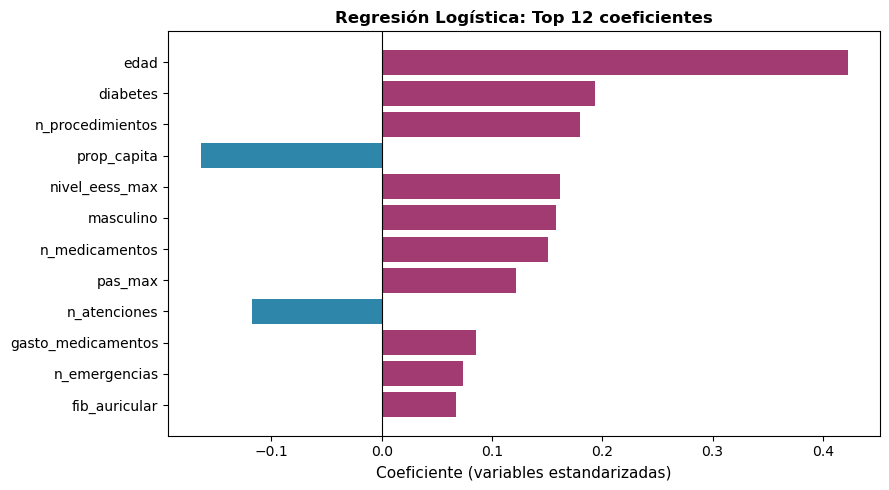

In [62]:
coefs = pd.Series(lr_final.coef_[0], index=X.columns)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(12)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top.index, top.values, color=[color_accent2 if v > 0 else color_accent1 for v in top.values])
ax.invert_yaxis()
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Coeficiente (variables estandarizadas)', fontsize=11)
ax.set_title('Regresión Logística: Top 12 coeficientes', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

---

## 8. Comparación de Modelos

### 8.1 Métricas de Clasificación (conjunto de prueba)
**Accuracy** engaña con desbalance (decir siempre "sin complicación" da ≈95%). Las métricas relevantes son:
- **Recall**: de los pacientes que sí tuvieron complicación, ¿cuántos detectó el modelo? (un falso negativo es un paciente en riesgo no detectado).
- **Precision**: de los que el modelo marcó como riesgo, ¿cuántos realmente la tuvieron?
- **F1**: equilibrio entre precision y recall.
- **ROC-AUC**: capacidad de **ordenar** a los pacientes por riesgo, independiente del umbral. Es la métrica principal de comparación.
- **PR-AUC** (*average precision*): resume la curva precision-recall. Es más exigente con el desbalance; un modelo aleatorio obtiene la prevalencia (≈0.056). Se agrega para comparar con `03_random_forest.ipynb`.

In [63]:
models = {
    'KNN': (y_pred_knn, y_proba_knn),
    'Árbol': (y_pred_dt, y_proba_dt),
    'Reg. Logística': (y_pred_lr, y_proba_lr),
}

metrics_df = pd.DataFrame([{
    'Modelo': name,
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred, zero_division=0),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred),
    'ROC-AUC': roc_auc_score(y_test, y_proba),
    'PR-AUC': average_precision_score(y_test, y_proba),     # métrica complementaria para clases desbalanceadas
} for name, (y_pred, y_proba) in models.items()])
print(f"PR-AUC de un modelo aleatorio = prevalencia = {y_test.mean():.4f}")
metrics_df.round(4)

PR-AUC de un modelo aleatorio = prevalencia = 0.0560


,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,KNN,0.9440,0.0000,0.0000,0.0000,0.6809,0.1120
1,Árbol,0.6082,0.0892,0.6501,0.1568,0.6745,0.1023
2,Reg. Logística,0.6493,0.0966,0.6297,0.1675,0.6925,0.1161


> **Nota sobre KNN:** KNN no admite `class_weight`. Con el umbral de 0.5, un paciente solo se marca como riesgo si la mayoría de sus vecinos tuvo complicación, algo raro cuando solo el 5% la tiene. Por eso su *recall* sale muy bajo aunque su AUC no sea malo. Para compararlo de forma justa se usa el AUC, que no depende del umbral.

### 8.2 Curvas ROC

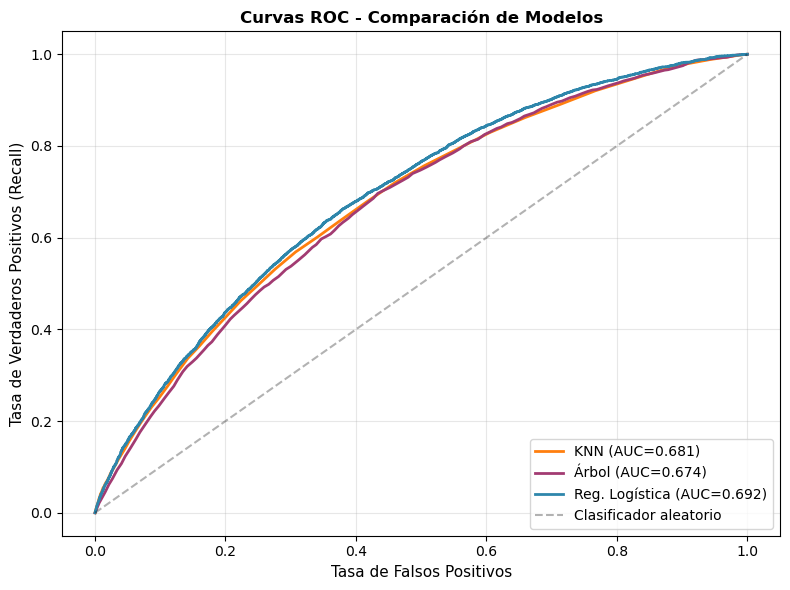

In [64]:
fig, ax = plt.subplots(figsize=(8, 6))
colors_roc = {'KNN': color_secondary, 'Árbol': color_accent2, 'Reg. Logística': color_accent1}

for name, (y_pred, y_proba) in models.items():
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    ax.plot(fpr, tpr, label=f'{name} (AUC={roc_auc_score(y_test, y_proba):.3f})',
            color=colors_roc[name], linewidth=2)

ax.plot([0, 1], [0, 1], 'k--', alpha=0.3, label='Clasificador aleatorio')
ax.set_xlabel('Tasa de Falsos Positivos', fontsize=11)
ax.set_ylabel('Tasa de Verdaderos Positivos (Recall)', fontsize=11)
ax.set_title('Curvas ROC - Comparación de Modelos', fontsize=12, fontweight='bold')
ax.legend(loc='lower right', fontsize=10)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 8.3 Matrices de Confusión

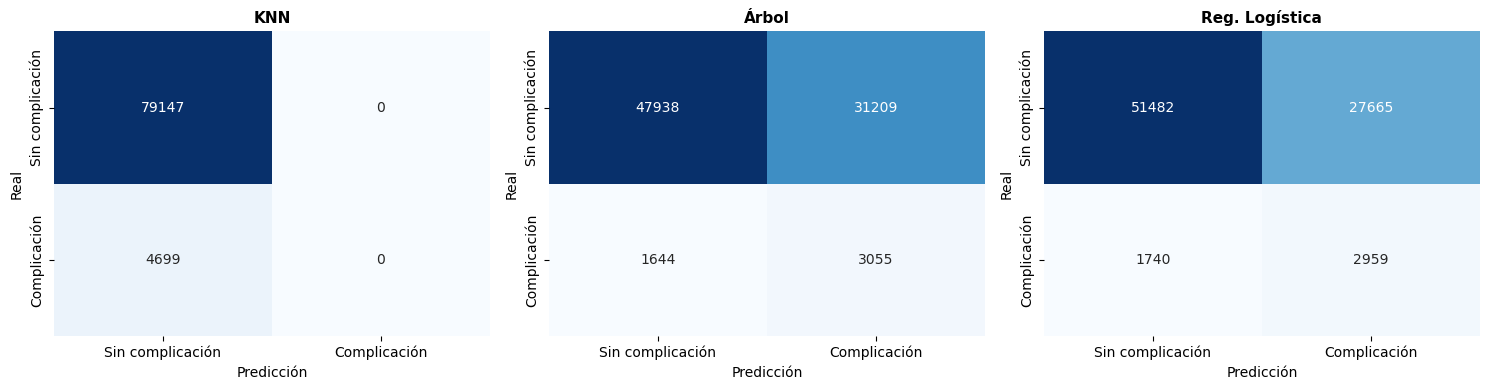

In [65]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
etiquetas = ['Sin complicación', 'Complicación']

for ax, (name, (y_pred, _)) in zip(axes.flatten(), models.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
                xticklabels=etiquetas, yticklabels=etiquetas)
    ax.set_title(name, fontsize=11, fontweight='bold')
    ax.set_ylabel('Real', fontsize=10)
    ax.set_xlabel('Predicción', fontsize=10)

plt.tight_layout()
plt.show()

### 8.4 ¿A cuántos pacientes en riesgo captura cada modelo? (deciles de riesgo)
Con el umbral de 0.5 los modelos con `class_weight` marcan a más de un tercio de los pacientes, y KNN a ninguno. Un programa de prevención del SIS no funciona así: tiene capacidad para seguir a un **porcentaje fijo** de pacientes. La pregunta útil es: *si se sigue al X% de pacientes con mayor riesgo, ¿qué porcentaje de las complicaciones se concentra en ellos?*

Como el porcentaje se fija de antemano (no se optimiza con el test), esta evaluación no tiene fuga de información. El **lift** indica cuántas veces más complicaciones hay en ese grupo que en un grupo elegido al azar.

KNN                      \
      Complicaciones capturadas (%) Precision (%)  Lift   
Top %                                                     
5                             13.71         15.36  2.74   
10                            23.83         13.36  2.38   
20                            40.60         11.38  2.03   
30                            54.42         10.17  1.81   

                              Árbol                      \
      Complicaciones capturadas (%) Precision (%)  Lift   
Top %                                                     
5                             12.07         13.53  2.41   
10                            22.43         12.57  2.24   
20                            39.05         10.94  1.95   
30                            52.25          9.76  1.74   

                     Reg. Logística                      
      Complicaciones capturadas (%) Precision (%)  Lift  
Top %                                                    
5                             14.47         16.22  2.89  
10                            24.60         13.79  2.46  
20                            41.75         11.70  2.09  
30                            55.35         10.34  1.85

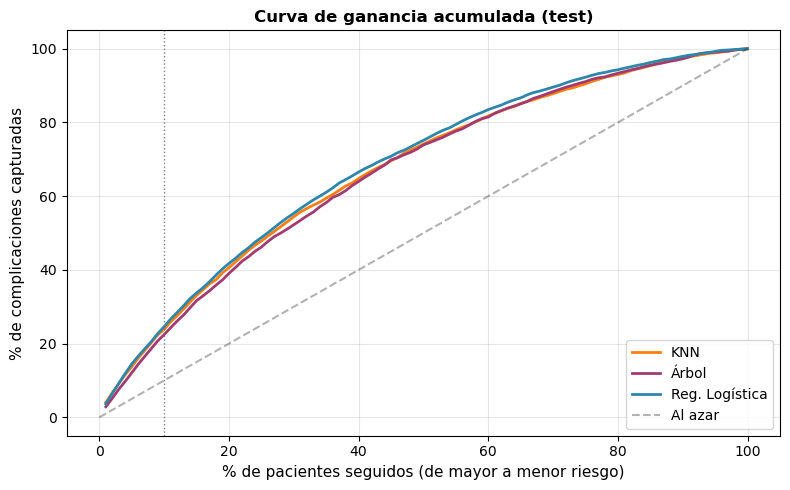

In [66]:
def captura(y_true, prob, porcentajes=(5, 10, 20, 30)):
    orden = np.argsort(-prob)
    y_ord = np.asarray(y_true)[orden]
    filas = []
    for p in porcentajes:
        n = int(len(y_ord) * p / 100)
        filas.append({'Top %': p, 'Complicaciones capturadas (%)': y_ord[:n].sum() / y_ord.sum() * 100,
                      'Precision (%)': y_ord[:n].mean() * 100, 'Lift': y_ord[:n].mean() / y_ord.mean()})
    return pd.DataFrame(filas)

tabla_captura = pd.concat({nombre: captura(y_test, prob).set_index('Top %') for nombre, (_, prob) in models.items()}, axis=1)
display(tabla_captura.round(2))

fig, ax = plt.subplots(figsize=(8, 5))
x_pct = np.arange(1, 101)
for (nombre, (_, prob)), color in zip(models.items(), [color_secondary, color_accent2, color_accent1]):
    y_ord = y_test.values[np.argsort(-prob)]
    acumulado = np.cumsum(y_ord) / y_ord.sum() * 100
    ax.plot(x_pct, acumulado[(x_pct * len(y_ord) // 100) - 1], label=nombre, color=color, linewidth=2)
ax.plot([0, 100], [0, 100], 'k--', alpha=0.3, label='Al azar')
ax.axvline(10, color='gray', linestyle=':', linewidth=1)
ax.set_xlabel('% de pacientes seguidos (de mayor a menor riesgo)', fontsize=11)
ax.set_ylabel('% de complicaciones capturadas', fontsize=11)
ax.set_title('Curva de ganancia acumulada (test)', fontsize=12, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Cómo leerlo.** Cuanto más arriba esté la curva, más complicaciones concentra el modelo en los pacientes que marca primero. Por ejemplo, si con el top 10% se captura el 25% de las complicaciones, el lift es 2.5: en ese grupo hay 2.5 veces más complicaciones que en uno elegido al azar. Esta tabla es más útil para decidir que el umbral de 0.5, porque se traduce directamente en cuántos pacientes puede seguir el sistema y cuántos casos se previenen.

### 8.5 Calibración: ¿las probabilidades son creíbles?
Si un modelo dice "10% de riesgo", aproximadamente 10 de cada 100 pacientes así deberían complicarse. La curva agrupa a los pacientes de test en 10 grupos según su probabilidad predicha y compara la media predicha con la proporción real. La diagonal es la calibración perfecta. El **Brier score** resume el error de las probabilidades (menor es mejor).

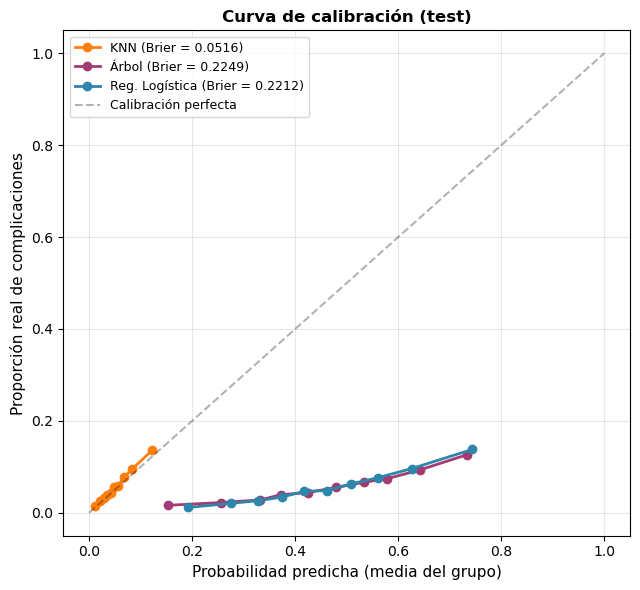

In [67]:
fig, ax = plt.subplots(figsize=(6.5, 6))
for (nombre, (_, prob)), color in zip(models.items(), [color_secondary, color_accent2, color_accent1]):
    real, predicha = calibration_curve(y_test, prob, n_bins=10, strategy='quantile')
    ax.plot(predicha, real, marker='o', color=color, linewidth=2, label=f'{nombre} (Brier = {brier_score_loss(y_test, prob):.4f})')
ax.plot([0, 1], [0, 1], 'k--', alpha=0.3, label='Calibración perfecta')
ax.set_xlabel('Probabilidad predicha (media del grupo)', fontsize=11)
ax.set_ylabel('Proporción real de complicaciones', fontsize=11)
ax.set_title('Curva de calibración (test)', fontsize=12, fontweight='bold')
ax.legend(fontsize=9, loc='upper left')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Cómo leerlo.** El Árbol y la Regresión Logística se entrenaron con `class_weight='balanced'`, que hace que el modelo "vea" a los positivos como si fueran la mitad de los pacientes: sus probabilidades **sobrestiman** mucho el riesgo (puntos por debajo de la diagonal), aunque eso no afecta al ROC-AUC. KNN, sin pesos, queda más cerca de la diagonal. Para comunicar riesgos individuales habría que entrenar sin pesos o recalibrar (ver `03_random_forest.ipynb`, donde el bosque sin pesos queda bien calibrado).

### 8.6 Intervalos de confianza (bootstrap)
Las diferencias de AUC entre modelos son de centésimas. Para saber si son reales o pueden deberse al azar del conjunto de test, se remuestrea el test con reemplazo 300 veces y se recalcula el AUC de cada modelo **sobre los mismos pacientes** (bootstrap pareado). El intervalo del 95% va del percentil 2.5 al 97.5. Si el intervalo de una **diferencia** no incluye el 0, la diferencia es significativa.

In [68]:
rng = np.random.default_rng(SEED)
y_arr = y_test.values
probs = {nombre: prob for nombre, (_, prob) in models.items()}
boot = {nombre: [] for nombre in probs}
for _ in range(300):
    idx_b = rng.integers(0, len(y_arr), len(y_arr))
    if y_arr[idx_b].sum() == 0:
        continue
    for nombre, prob in probs.items():
        boot[nombre].append(roc_auc_score(y_arr[idx_b], prob[idx_b]))
boot = pd.DataFrame(boot)

ic = pd.DataFrame({'ROC-AUC test': {n: roc_auc_score(y_test, p) for n, p in probs.items()},
                   'IC 95% inferior': boot.quantile(0.025), 'IC 95% superior': boot.quantile(0.975)})
display(ic.round(4))

difs = pd.DataFrame({
    'Reg. Logística − Árbol': boot['Reg. Logística'] - boot['Árbol'],
    'Reg. Logística − KNN': boot['Reg. Logística'] - boot['KNN'],
    'Árbol − KNN': boot['Árbol'] - boot['KNN'],
})
display(pd.DataFrame({'Diferencia media': difs.mean(), 'IC 95% inferior': difs.quantile(0.025),
                      'IC 95% superior': difs.quantile(0.975),
                      '¿Significativa?': (difs.quantile(0.025) > 0) | (difs.quantile(0.975) < 0)}).round(4))

,ROC-AUC test,IC 95% inferior,IC 95% superior
KNN,0.6809,0.6739,0.6878
Árbol,0.6745,0.6679,0.6820
Reg. Logística,0.6925,0.6852,0.7001


,Diferencia media,IC 95% inferior,IC 95% superior,¿Significativa?
Reg. Logística − Árbol,0.0181,0.0130,0.0224,True
Reg. Logística − KNN,0.0116,0.0068,0.0158,True
Árbol − KNN,-0.0065,-0.0124,-0.0010,True


**Cómo leerlo.** Los intervalos individuales suelen tener un ancho de ≈±0.01. Aunque se superpongan, la diferencia **pareada** puede ser significativa, porque los dos modelos se evalúan sobre los mismos pacientes y gran parte del ruido se cancela. Una diferencia significativa pero pequeña (p. ej. 0.015) es real, pero hay que valorar si justifica un modelo más complejo.

### 8.7 ¿Riesgo clínico o uso del sistema de salud?
Varias de las variables más relacionadas con `y` no describen el estado clínico del paciente sino **cómo y dónde se atiende**: `prop_capita`, `nivel_eess_max`, conteos de atenciones y consumos, gasto. Un paciente atendido en un hospital tiene más oportunidades de que se le **registre** un diagnóstico de insuficiencia cardíaca o enfermedad renal (sesgo de detección). Para medir cuánto de la predicción viene de cada fuente, se entrena la Regresión Logística (mismos hiperparámetros) con tres conjuntos de variables.

In [69]:
CLINICAS = ['edad', 'masculino', 'pas_media', 'pas_max', 'pad_max', 'presion_pulso', 'presion_pulso_max', 'prop_pa_alta',
            'pas_ultima', 'sin_medicion_pa', 'diabetes', 'dislipidemia', 'obesidad', 'fib_auricular', 'cardiopatia',
            'hta_cardiaca', 'n_comorbilidades']
CLINICAS = [c for c in CLINICAS if c in X.columns]
USO_SISTEMA = [c for c in X.columns if c not in CLINICAS]
print("Clínicas y demográficas:", CLINICAS)
print("Uso del sistema de salud y ubicación del establecimiento:", USO_SISTEMA)

def rl_con(columnas):
    pipe = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler()),
                     ('model', LogisticRegression(C=best_C, solver=best_solver, class_weight='balanced', max_iter=1000, random_state=SEED))])
    pipe.fit(X_train[columnas], y_train)
    prob = pipe.predict_proba(X_test[columnas])[:, 1]
    return {'Variables': len(columnas), 'ROC-AUC test': roc_auc_score(y_test, prob), 'PR-AUC test': average_precision_score(y_test, prob)}

conjuntos = pd.DataFrame({'Todas': rl_con(list(X.columns)), 'Solo clínicas y demográficas': rl_con(CLINICAS),
                          'Solo uso del sistema': rl_con(USO_SISTEMA)}).T
conjuntos['Variables'] = conjuntos['Variables'].astype(int)
conjuntos.round(4)

Clínicas y demográficas: ['edad', 'masculino', 'pas_media', 'pas_max', 'pad_max', 'presion_pulso', 'presion_pulso_max', 'prop_pa_alta', 'pas_ultima', 'sin_medicion_pa', 'diabetes', 'dislipidemia', 'obesidad', 'fib_auricular', 'cardiopatia', 'hta_cardiaca', 'n_comorbilidades']
Uso del sistema de salud y ubicación del establecimiento: ['es_lima_frecuente', 'altitud_msnm', 'n_atenciones', 'n_emergencias', 'n_hospitalizaciones', 'n_mediciones_pa', 'prop_capita', 'nivel_eess_max', 'dias_desde_ultima', 'n_diagnosticos', 'n_medicamentos', 'gasto_medicamentos', 'n_procedimientos', 'gasto_procedimientos', 'n_insumos', 'gasto_insumos', 'polifarmacia']


,Variables,ROC-AUC test,PR-AUC test
Todas,34,0.6925,0.1161
Solo clínicas y demográficas,17,0.6492,0.1004
Solo uso del sistema,17,0.6374,0.0927


**Cómo leerlo.**
- Si el modelo **solo clínico** pierde poco frente al completo, el riesgo se explica sobre todo por características del paciente, y las variables de uso aportan poco.
- Si el modelo **solo de uso del sistema** se acerca al completo, una parte importante de lo que el modelo "predice" es el acceso a la atención y la probabilidad de que el diagnóstico se registre, no necesariamente un mayor riesgo clínico. No invalida el modelo (el uso del sistema también refleja gravedad), pero es una **limitación** que debe declararse en el informe.

### 8.8 Desempeño por subgrupos
Un modelo puede tener buen AUC global y funcionar peor en algún grupo. Se calcula el AUC de la Regresión Logística por sexo, edad y región del establecimiento. Dentro de un subgrupo el AUC suele ser menor que el global, porque la variable que define el grupo (p. ej. la edad) ya no ayuda a separar a los pacientes.

In [70]:
grupos_test = {
    'Sexo': X_test['masculino'].map({0: 'Mujer', 1: 'Hombre'}),
    'Edad': pd.cut(X_test['edad'], [0, 60, 75, 200], right=False, labels=['< 60', '60-74', '≥ 75']),
    'Región': X_test['es_lima_frecuente'].map({0: 'Fuera de Lima', 1: 'Lima'}),
}
filas = []
for variable, grupo in grupos_test.items():
    for valor in grupo.dropna().unique():
        m = (grupo == valor).values
        filas.append({'Variable': variable, 'Grupo': valor, 'Pacientes': int(m.sum()), '% y=1': y_test[m].mean() * 100,
                      'ROC-AUC (RL)': roc_auc_score(y_test[m], y_proba_lr[m])})
pd.DataFrame(filas).set_index(['Variable', 'Grupo']).sort_index().round(3)

Pacientes  % y=1  ROC-AUC (RL)
Variable Grupo                                        
Edad     60-74              33288  5.846         0.670
         < 60               26674  3.711         0.717
         ≥ 75               23884  7.382         0.659
Región   Fuera de Lima      60213  4.989         0.693
         Lima               23633  7.172         0.674
Sexo     Hombre             28150  6.799         0.670
         Mujer              55696  5.000         0.698

**Cómo leerlo.** Diferencias de AUC de unas centésimas entre grupos son normales. Si algún grupo queda muy por debajo (p. ej. 0.05 menos), el modelo funciona peor para esos pacientes y convendría investigar por qué (menos datos, otro patrón de atención, menos mediciones de presión).

---

## 9. Pipelines

Los pipelines encapsulan **imputación → (estandarización) → modelo**. Con `fit(X_train)`, cada paso aprende solo del train, y con `predict(X_test)` se aplican las medianas y escalas de train. Se entrenan con `X_train` **crudo (con NaN)** y deben reproducir los resultados del flujo manual.

In [71]:
pipelines = {
    'KNN': Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler()),
                     ('model', KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1))]),
    'Árbol': Pipeline([('imputer', SimpleImputer(strategy='median')),
                       ('model', DecisionTreeClassifier(max_depth=best_depth, min_samples_split=20, min_samples_leaf=best_leaf,
                                                        class_weight='balanced', random_state=SEED))]),
    'Reg. Logística': Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler()),
                                ('model', LogisticRegression(C=best_C, solver=best_solver,
                                                             class_weight='balanced', max_iter=1000,
                                                             random_state=SEED))]),
}

for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    auc_pipe = roc_auc_score(y_test, pipe.predict_proba(X_test)[:, 1])
    auc_manual = metrics_df.set_index('Modelo').loc[name, 'ROC-AUC']
    print(f"{name:15s} (Pipeline): ROC-AUC = {auc_pipe:.4f} | manual = {auc_manual:.4f}")

KNN             (Pipeline): ROC-AUC = 0.6809 | manual = 0.6809
Árbol           (Pipeline): ROC-AUC = 0.6745 | manual = 0.6745
Reg. Logística  (Pipeline): ROC-AUC = 0.6925 | manual = 0.6925


---
## APÉNDICE

### Validación Cruzada: Estimación de Variabilidad
Con los hiperparámetros ya elegidos, `StratifiedKFold` (5 folds) mide la **estabilidad** de cada modelo. Se usan los **pipelines**: la imputación y el escalado se ajustan **dentro de cada fold**, sin fuga de información. Para que KNN sea manejable, la validación cruzada se hace sobre una **submuestra estratificada de 50,000 pacientes**.

In [72]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

idx_cv, _ = train_test_split(X.index, train_size=50_000, random_state=SEED, stratify=y)
X_cv, y_cv = X.loc[idx_cv], y.loc[idx_cv]

cv_results, cv_scores_dict = [], {}
for name, pipe in pipelines.items():
    scores = cross_val_score(pipe, X_cv, y_cv, cv=skf, scoring='roc_auc')
    cv_results.append({'Modelo': name, 'ROC-AUC Media': scores.mean(), 'Desv. Estándar': scores.std()})
    cv_scores_dict[name] = scores

cv_results_df = pd.DataFrame(cv_results)
cv_results_df.round(4)

,Modelo,ROC-AUC Media,Desv. Estándar
0,KNN,0.6690,0.0174
1,Árbol,0.6566,0.0126
2,Reg. Logística,0.6902,0.0177


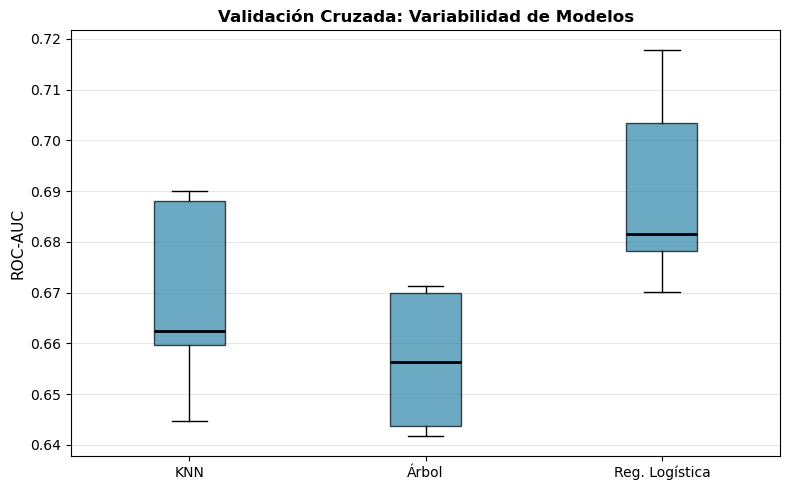

In [73]:
fig, ax = plt.subplots(figsize=(8, 5))
bp = ax.boxplot([cv_scores_dict[n] for n in pipelines], tick_labels=list(pipelines), patch_artist=True,
                medianprops=dict(color='black', linewidth=2))
for patch in bp['boxes']:
    patch.set_facecolor(color_accent1)
    patch.set_alpha(0.7)
ax.set_ylabel('ROC-AUC', fontsize=11)
ax.set_title('Validación Cruzada: Variabilidad de Modelos', fontsize=12, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [74]:
# Cifras clave de esta ejecución, para redactar las conclusiones
resumen_final = metrics_df.set_index('Modelo')[['ROC-AUC', 'PR-AUC', 'Recall', 'Precision']].join(ic[['IC 95% inferior', 'IC 95% superior']]).join(
    pd.Series({n: brier_score_loss(y_test, p) for n, p in probs.items()}, name='Brier')).join(
    cv_results_df.set_index('Modelo').rename(columns={'ROC-AUC Media': 'ROC-AUC CV (50k)', 'Desv. Estándar': 'Desv. CV'}))
print(f"Pacientes: {len(df):,} | Variables usadas: {X.shape[1]} | Tasa de complicación: {y.mean():.2%} "
      f"(desbalance {(1 - y.mean()) / y.mean():.1f}:1) | Sin medición de PA: {df['sin_medicion_pa'].mean():.1%}")
print(f"Hiperparámetros elegidos -> KNN: k={best_k} | Árbol: profundidad={best_depth}, min_samples_leaf={best_leaf} | RL: solver={best_solver}, C={best_C}")
resumen_final.round(4)

Pacientes: 419,226 | Variables usadas: 34 | Tasa de complicación: 5.60% (desbalance 16.8:1) | Sin medición de PA: 3.9%
Hiperparámetros elegidos -> KNN: k=301 | Árbol: profundidad=10, min_samples_leaf=2000 | RL: solver=lbfgs, C=0.001


,ROC-AUC,PR-AUC,Recall,Precision,IC 95% inferior,IC 95% superior,Brier,ROC-AUC CV (50k),Desv. CV
Modelo,,,,,,,,,
KNN,0.6809,0.1120,0.0000,0.0000,0.6739,0.6878,0.0516,0.6690,0.0174
Árbol,0.6745,0.1023,0.6501,0.0892,0.6679,0.6820,0.2249,0.6566,0.0126
Reg. Logística,0.6925,0.1161,0.6297,0.0966,0.6852,0.7001,0.2212,0.6902,0.0177


## 10. Conclusiones
*Las cifras corresponden a la ejecución del 17-nov con el dataset actual (419,226 pacientes, 5.60% de complicaciones); las de las secciones nuevas se completan con la tabla de la celda anterior y las secciones 8.4-8.8.*

1. **Datos:** 419,226 pacientes, 34 variables y 5.60% de complicaciones (desbalance ≈17:1). No hay pacientes repetidos. Los faltantes (3.9% sin medición de presión) se imputaron con la mediana de train y se conservó `sin_medicion_pa`. Se eliminaron `dias_hosp` (Spearman 0.997 con `n_hospitalizaciones`) y `pad_media` (dependencia exacta con `presion_pulso` y `pas_media`).
2. **Mejor modelo: Regresión Logística** (ROC-AUC test 0.692, PR-AUC 0.116; CV 0.690 ± 0.018), seguida del Árbol (0.674) y KNN (0.662). Es también la más estable y no sobreajusta. Las variables nuevas del preprocesamiento no cambiaron el ranking ni mejoraron el AUC de forma apreciable (versión anterior: 0.695).
3. **¿Las diferencias son reales?** Ver los intervalos bootstrap pareados (sección 8.6).
4. **El accuracy engaña:** KNN tiene el mayor accuracy (94.4%) porque **no predice ninguna complicación** (recall = 0). Con `class_weight='balanced'`, el Árbol y la RL detectan ≈61-63% de los pacientes que se complicarán con el umbral 0.5, a costa de muchos falsos positivos (precision ≈ 9-10%). La tabla de captura por deciles (sección 8.4) traduce esto a una regla operativa: qué porcentaje de las complicaciones se concentra en el 10% de pacientes de mayor riesgo.
5. **Calibración:** los modelos con pesos de clase sobrestiman el riesgo; sus probabilidades sirven para **ordenar** pacientes, no para comunicar riesgos individuales (sección 8.5).
6. **Riesgo clínico vs. uso del sistema:** las variables más correlacionadas con `y` son `prop_capita` (−0.092) y `nivel_eess_max` (+0.081), por encima de la edad. La comparación de la sección 8.7 indica cuánto de la predicción depende del acceso a la atención (posible sesgo de detección), una limitación que debe declararse.
7. **KNN es el modelo más débil para estos datos** por la alta dimensionalidad, el desbalance y el costo de inferencia (sección 5).
8. **Capacidad predictiva moderada (AUC ≈ 0.66-0.69).** Es esperable con datos administrativos sin laboratorio (creatinina, colesterol, HbA1c). Ningún modelo pasa de 0.85, así que no hay señales de fuga de información.
9. **Los pipelines reproducen exactamente** los resultados del flujo manual: la imputación y el escalado se ajustan solo con train.
10. **Siguientes pasos:** modelos de ensamble (`03_random_forest.ipynb`, ROC-AUC 0.705 con la misma partición), recalibración, variables de laboratorio o de medicamentos antihipertensivos y validación temporal (entrenar con 2022→2023 y evaluar con 2023→2024).